# 2 · Reconstructing what was known before tipoff

The EDA suggested season strength, recent team form, player roles and rest as plausible signals. Now the question is operational: **could every value in a forecast have been calculated before that game?**

I work through Clippers at Thunder on December 15, 2018, using only earlier records. The example was chosen by a calendar/history rule—Oklahoma City's first home game after at least 25 prior games that season—not by whether a prediction worked. The same calculations run for all teams and seasons in `src/features.py`.

The output is one game row with signed home-minus-away differences. Raw outcomes remain available for evaluation but are excluded from the model's explicit input list.

In [1]:
from pathlib import Path
import sys, json

ROOT = Path.cwd() if (Path.cwd() / "Data").exists() else Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src.charts import feature_label

TABLES = ROOT / "artifacts/tables"
FIGURES = ROOT / "artifacts/figures"
CLAY, TEAL = "#b55832", "#427b83"
plt.rcParams.update(
    {
        "axes.spines.top": False,
        "axes.spines.right": False,
        "figure.figsize": (9, 4),
        "axes.grid": False,
        "font.size": 10,
    }
)
pd.set_option("display.max_columns", 14)


def finish(fig, filename=None):
    fig.tight_layout()
    if filename:
        fig.savefig(FIGURES / filename, dpi=160, bbox_inches="tight")
    plt.show()

In [2]:
from src.data import load_data, validate_data
from src.features import build_team_history, build_roster_history, feature_sets
from src.analysis import player_role_trace

raw_team, raw_player = load_data()
games, audit, _, _ = validate_data(raw_team, raw_player)
history = pd.read_csv(
    TABLES / "team_history.csv.gz",
    parse_dates=["gamedate", "history_end", "player_history_end"],
)
matchups = pd.read_csv(
    TABLES / "matchups.csv.gz",
    parse_dates=["gamedate", "home_history_end", "away_history_end"],
)
example = json.loads((TABLES / "worked_example.json").read_text())
game_id = example["game_id"]
current = matchups.set_index("nbagameid").loc[game_id]
cutoff = current.gamedate
display(pd.Series(example, name="Worked example").to_frame())

,Worked example
game_id,21800434
gamedate,2018-12-15
season,2018
home,OKC
away,LAC
prior_home_games,27
prior_away_games,28


## 1. Pair offense with the opponent's offense

The source row for OKC describes OKC's offense, including defensive rebounds conceded to the opponent. To get OKC's points allowed and defensive possessions, I join the other offensive row from each game. Both keys matter: the game and the opposing team. A validated one-to-one join guards against multiplying observations.

In [3]:
regular = games[games.gametype.eq(2)]
prior = regular[
    (regular.season == 2018) & regular.off_team.eq("OKC") & regular.gamedate.lt(cutoff)
].sort_values("gamedate")
previous_id = int(prior.iloc[-1].nbagameid)
display(
    raw_team.loc[
        raw_team.nbagameid.eq(previous_id),
        [
            "nbagameid",
            "off_team",
            "def_team",
            "points",
            "possessions",
            "reboffensive",
            "rebdefensive",
            "reboundchance",
        ],
    ]
)
display(
    prior[
        [
            "gamedate",
            "off_team",
            "points",
            "possessions",
            "opp_points",
            "opp_possessions",
        ]
    ].tail(3)
)
assert not games.duplicated(["nbagameid", "off_team"]).any()
assert prior.gamedate.max() < cutoff

,nbagameid,off_team,def_team,points,possessions,reboffensive,rebdefensive,reboundchance
12115,21800426,DEN,OKC,109,96,15,27,42
12116,21800426,OKC,DEN,98,96,21,38,59


,gamedate,off_team,points,possessions,opp_points,opp_possessions
18569,2018-12-10,OKC,122,106,113,107
17733,2018-12-12,OKC,114,107,118,108
12116,2018-12-14,OKC,98,96,109,96


This produces the correct defensive perspective without summing overlapping player on-court totals. It also gives a useful audit trail: the latest source game must precede the target date. The raw current-game points are not needed anywhere in this calculation.

## 2. Turn earlier totals into season strength

I sum the numerators and denominators separately, then divide. This respects possessions and attempts; averaging game-level percentages would weight a low-denominator game as much as a high-denominator game.

In [4]:
totals = pd.read_csv(TABLES / "worked_team_totals.csv")
totals["net_rating"] = totals.ortg - totals.drtg
totals["win_pct"] = totals.prior_wins / totals.prior_games
display(
    totals[
        [
            "team",
            "prior_games",
            "prior_wins",
            "points",
            "possessions",
            "opponent_points",
            "opponent_possessions",
            "ortg",
            "drtg",
            "net_rating",
            "win_pct",
        ]
    ].round(3)
)
manual_ortg = 100 * prior.points.sum() / prior.possessions.sum()
manual_drtg = 100 * prior.opp_points.sum() / prior.opp_possessions.sum()
np.testing.assert_allclose(
    [manual_ortg, manual_drtg, manual_ortg - manual_drtg],
    [current.home_ortg, current.home_drtg, current.home_net_rating],
    atol=1e-7,
)
print("Raw prior totals reproduce the stored OKC ratings.")

,team,prior_games,prior_wins,points,possessions,opponent_points,opponent_possessions,ortg,drtg,net_rating,win_pct
0,OKC,27,17,3001,2764,2845,2764,108.575,102.931,5.644,0.630
1,LAC,28,17,3200,2862,3181,2869,111.810,110.875,0.935,0.607


Raw prior totals reproduce the stored OKC ratings.


The two teams have played different numbers of games. That is why the simple record rule compares winning **percentage**, not total wins. It is also why per-possession rates are more comparable than raw points per season.

## 3. Make the shift visible

The most important operation is easy to hide in a helper: shift before accumulating. Here I show the last few rows of the actual team sequence. The “including current game” value is deliberately calculated as a contrast and never enters a candidate model.

In [5]:
sequence = (
    regular[
        (regular.season == 2018)
        & regular.off_team.eq("OKC")
        & regular.gamedate.le(cutoff)
    ]
    .sort_values("gamedate")
    .copy()
)
sequence["prior_points"] = sequence.points.shift(1).expanding().sum()
sequence["prior_possessions"] = sequence.possessions.shift(1).expanding().sum()
sequence["pregame_ortg"] = 100 * sequence.prior_points / sequence.prior_possessions
sequence["including_current_game"] = (
    100 * sequence.points.cumsum() / sequence.possessions.cumsum()
)
display(
    sequence[
        [
            "gamedate",
            "points",
            "possessions",
            "prior_points",
            "prior_possessions",
            "pregame_ortg",
            "including_current_game",
        ]
    ]
    .tail(6)
    .round({"pregame_ortg": 3, "including_current_game": 3})
)
assert np.isclose(sequence.iloc[-1].pregame_ortg, current.home_ortg)

,gamedate,points,possessions,prior_points,prior_possessions,pregame_ortg,including_current_game
12850,2018-12-05,114,102,2441.0,2246.0,108.682,108.816
20883,2018-12-07,112,107,2555.0,2348.0,108.816,108.635
18569,2018-12-10,122,106,2667.0,2455.0,108.635,108.903
17733,2018-12-12,114,107,2789.0,2561.0,108.903,108.808
12116,2018-12-14,98,96,2903.0,2668.0,108.808,108.575
23161,2018-12-15,110,103,3001.0,2764.0,108.575,108.511


The last row's pregame value contains no part of December 15's box score. If the current points changed, its postgame cumulative value would move and its pregame value would not. Grouping by season/team also prevents a new season from inheriting a completed future season total.

## 4. Build rates with basketball-specific denominators

Effective field goal percentage credits the extra value of a three. Turnover rate uses the supplied shot-attempt definition, which includes shooting fouls. Defensive rebounding is easy to get wrong because `rebdefensive` in an offensive row belongs to the defending opponent.

In [6]:
opponent_rows = raw_team[
    raw_team.nbagameid.isin(prior.nbagameid) & raw_team.def_team.eq("OKC")
]
rates = pd.DataFrame(
    [
        [
            "efg",
            prior.fgmade.sum() + 0.5 * prior.fg3made.sum(),
            prior.fgattempted.sum(),
        ],
        [
            "tov_rate",
            prior.turnovers.sum(),
            prior.shotattempts.sum() + prior.turnovers.sum(),
        ],
        ["oreb_rate", prior.reboffensive.sum(), prior.reboundchance.sum()],
        [
            "dreb_rate",
            opponent_rows.rebdefensive.sum(),
            opponent_rows.reboundchance.sum(),
        ],
        ["ft_rate", prior.ftattempted.sum(), prior.fgattempted.sum()],
    ],
    columns=["measure", "numerator", "denominator"],
)
rates["manual_value"] = rates.numerator / rates.denominator
rates["stored_value"] = [current["home_" + m] for m in rates.measure]
display(rates.round(5))
np.testing.assert_allclose(rates.manual_value, rates.stored_value, atol=1e-8)

,measure,numerator,denominator,manual_value,stored_value
0,efg,1264.0,2496,0.50641,0.50641
1,tov_rate,403.0,3110,0.12958,0.12958
2,oreb_rate,463.0,1465,0.31604,0.31604
3,dreb_rate,1004.0,1378,0.72859,0.72859
4,ft_rate,673.0,2496,0.26963,0.26963


Every displayed ratio reconciles to the stored pregame row. I retain both the rate definition and the historical cutoff because a mathematically correct ratio can still be an invalid forecast input if its numerator contains the target game.

## 5. Compare rolling form with the season view

The window is measured in previous team games, not calendar days. The same shift applies before rolling. Five games react quickly; twenty provide more stable denominators. These windows are candidates, not an assumption that a recent streak should override team strength.

In [7]:
rolling = []
for n in [5, 10, 20]:
    p = prior.tail(n)
    net = (
        100 * p.points.sum() / p.possessions.sum()
        - 100 * p.opp_points.sum() / p.opp_possessions.sum()
    )
    efg = (p.fgmade.sum() + 0.5 * p.fg3made.sum()) / p.fgattempted.sum()
    rolling.append(
        {
            "prior_window": n,
            "games_available": len(p),
            "net_rating": net,
            "efg": efg,
            "first_source_date": p.gamedate.min(),
            "last_source_date": p.gamedate.max(),
        }
    )
    np.testing.assert_allclose(
        [net, efg],
        [current[f"home_last{n}_net_rating"], current[f"home_last{n}_efg"]],
        atol=1e-7,
    )
display(pd.DataFrame(rolling))
print("Season net rating:", round(current.home_net_rating, 3))

,prior_window,games_available,net_rating,efg,first_source_date,last_source_date
0,5,5,-0.738046,0.513187,2018-12-05,2018-12-14
1,10,10,5.274556,0.513187,2018-11-23,2018-12-14
2,20,20,8.422112,0.519053,2018-11-02,2018-12-14


Season net rating: 5.644


The current game is absent even when a window is full. Short-season histories use the available earlier games; the ten-game model warmup ensures a minimally useful recent sample but does not promise twenty prior games for every twenty-game candidate.

## 6. Use the schedule information actually available

I can derive days off, back-to-backs and game count from dates. I cannot derive actual travel burden or neutral-site status reliably from these files, so those stories stay out of the feature set.

In [8]:
last_date = prior.gamedate.max()
rest_days = min(max((cutoff - last_date).days - 1, 0), 7)
back_to_back = int((cutoff - last_date).days == 1)
games_last7 = prior.gamedate.ge(cutoff - pd.Timedelta(days=7)).sum()
display(prior[["gamedate", "off_team", "def_team"]].tail(7))
display(
    pd.Series(
        {
            "days_off_capped": rest_days,
            "back_to_back": back_to_back,
            "games_in_previous_seven_days": games_last7,
        },
        name="Before tipoff",
    ).to_frame()
)
np.testing.assert_array_equal(
    [rest_days, back_to_back, games_last7],
    [current.home_rest_days, current.home_back_to_back, current.home_games_last7],
)

,gamedate,off_team,def_team
19046,2018-11-30,OKC,ATL
17939,2018-12-03,OKC,DET
12850,2018-12-05,OKC,BKN
20883,2018-12-07,OKC,CHI
18569,2018-12-10,OKC,UTA
17733,2018-12-12,OKC,NOP
12116,2018-12-14,OKC,DEN


,Before tipoff
days_off_capped,0
back_to_back,1
games_in_previous_seven_days,3


## 7. Establish each player's role without consulting today's roster

The previous game's roster is the latest membership evidence. Within the prior twenty team games, I calculate each player's minutes per appearance with positive playing time, then normalize those normal-role minutes. This gives regulars meaningful weight even if they have recently missed games, but cannot know a same-day arrival or departure.

,player_name,seconds,appearances,role_minutes,role_weight,rostered_games,participation,absence
0,Paul George,41745.7,20,34.788,0.125,5,1.0,0.0
1,Russell Westbrook,28580.2,14,34.024,0.123,5,1.0,0.0
2,Steven Adams,39918.5,20,33.265,0.120,5,1.0,0.0
3,Jerami Grant,36545.6,20,30.455,0.110,5,1.0,0.0
4,Dennis Schröder,35590.4,20,29.659,0.107,5,1.0,0.0
5,Terrance Ferguson,18623.6,14,22.171,0.080,5,1.0,0.0
6,Alex Abrines,19461.3,17,19.080,0.069,5,1.0,0.0
7,Patrick Patterson,17550.1,20,14.625,0.053,5,1.0,0.0
8,Nerlens Noel,15933.8,19,13.977,0.050,5,1.0,0.0
9,Hamidou Diallo,11230.3,15,12.478,0.045,5,1.0,0.0


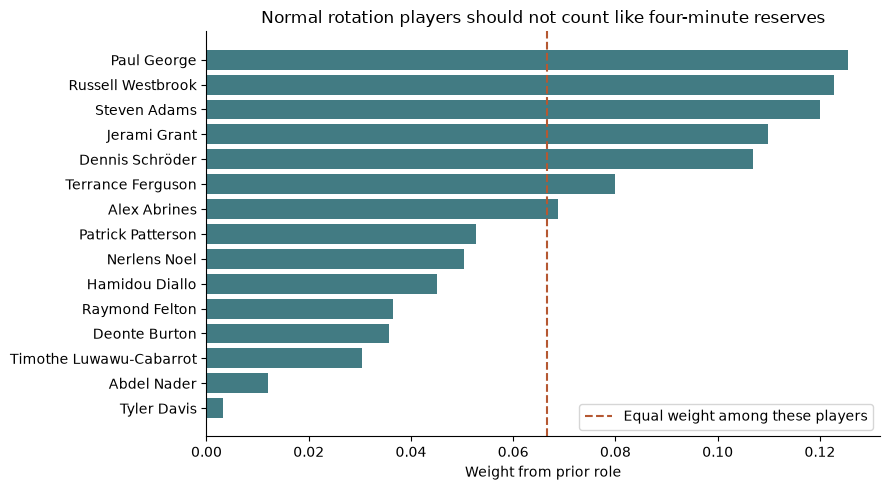

In [9]:
trace = player_role_trace(raw_player, history, game_id, "OKC")
display(
    trace[
        [
            "player_name",
            "seconds",
            "appearances",
            "role_minutes",
            "role_weight",
            "rostered_games",
            "participation",
            "absence",
        ]
    ].round(3)
)
assert np.isclose(trace.role_weight.sum(), 1)
assert pd.to_datetime(trace.history_end).max() < cutoff
fig, ax = plt.subplots(figsize=(9, 5))
ordered = trace.sort_values("role_weight")
ax.barh(ordered.player_name, ordered.role_weight, color=TEAL)
ax.axvline(
    1 / len(trace), linestyle="--", color=CLAY, label="Equal weight among these players"
)
ax.set(
    xlabel="Weight from prior role",
    title="Normal rotation players should not count like four-minute reserves",
)
ax.legend()
finish(fig, "story_worked_roles.png")

The denominator is the sum of role estimates, not a claim that those players will jointly play a fixed 240 minutes tonight. Minutes per appearance and recent total-minute share answer different questions. A newly rostered player with no earlier appearances has no estimated role; that uncertainty is a limitation, not a reason to use their current-game minutes.

## 8. Weight recent performance and participation by those roles

For scoring, each player's prior-five-game shot-attempt points are divided by shot attempts. Players with no attempts have no scoring-efficiency estimate; I renormalize the scoring weights over those with attempts. Historical absence and participation rates use prior rostered records, keeping the original role weights.

In [10]:
display(
    trace[
        [
            "player_name",
            "attempts",
            "attempt_points",
            "ppa",
            "scoring_weight",
            "ppa_contribution",
            "absence_contribution",
            "participation_contribution",
        ]
    ].round(4)
)
aggregates = pd.Series(
    {
        "Equal-weight recent PPA among observed scorers": trace.ppa.mean(),
        "Role-weighted recent PPA": trace.ppa_contribution.sum(),
        "Role-weighted historical absence": trace.absence_contribution.sum(),
        "Role-weighted participation": trace.participation_contribution.sum(),
    },
    name="Pregame OKC summary",
)
display(aggregates.to_frame().round(4))
np.testing.assert_allclose(
    [
        trace.ppa_contribution.sum(),
        trace.absence_contribution.sum(),
        trace.participation_contribution.sum(),
    ],
    [
        current.home_weighted_ppa,
        current.home_weighted_absence,
        current.home_weighted_participation,
    ],
    atol=1e-8,
)

,player_name,attempts,attempt_points,ppa,scoring_weight,ppa_contribution,absence_contribution,participation_contribution
0,Paul George,104,143,1.3750,0.1367,0.1880,0.0,0.1255
1,Russell Westbrook,103,89,0.8641,0.1337,0.1156,0.0,0.1227
2,Steven Adams,82,96,1.1707,0.1307,0.1531,0.0,0.1200
3,Jerami Grant,47,51,1.0851,0.1197,0.1299,0.0,0.1098
4,Dennis Schröder,79,87,1.1013,0.1166,0.1284,0.0,0.1070
5,Terrance Ferguson,19,25,1.3158,0.0871,0.1147,0.0,0.0800
6,Alex Abrines,15,8,0.5333,0.0750,0.0400,0.0,0.0688
7,Patrick Patterson,11,5,0.4545,0.0575,0.0261,0.0,0.0528
8,Nerlens Noel,22,18,0.8182,0.0549,0.0449,0.0,0.0504
9,Hamidou Diallo,15,14,0.9333,0.0490,0.0458,0.0,0.0450


,Pregame OKC summary
Equal-weight recent PPA among observed scorers,0.8774
Role-weighted recent PPA,0.9864
Role-weighted historical absence,0.0000
Role-weighted participation,0.9072


The calculation is visible down to each player's contribution. `missed` is used only after that earlier game has ended, and positive seconds override a contradictory flag. A DNP is nonparticipation but not automatically a recorded injury/suspension absence. None of these measures should be labeled a confirmed pregame injury report.

## 9. Measure concentration and continuity separately

Concentration asks who gets the minutes; continuity asks whether that allocation is changing. I compute both from individual prior minutes. Continuity is the overlap between player minute shares in the last five games and the five before them; identical distributions score one.

In [11]:
okc_history = history[
    (history.season == 2018) & history.off_team.eq("OKC")
].sort_values("gamedate")
past = okc_history[okc_history.gamedate.lt(cutoff)]


def minute_shares(ids):
    seconds = (
        raw_player[raw_player.team.eq("OKC") & raw_player.nbagameid.isin(ids)]
        .groupby("nbapersonid")
        .seconds.sum()
    )
    return seconds / seconds.sum()


last5 = minute_shares(past.nbagameid.tail(5))
previous5 = minute_shares(past.nbagameid.iloc[-10:-5])
share_table = pd.concat(
    [last5.rename("last5_share"), previous5.rename("previous5_share")], axis=1
).fillna(0)
share_table["overlap"] = share_table.min(axis=1)
last10 = minute_shares(past.nbagameid.tail(10))
display(share_table.sort_values("last5_share", ascending=False).head(10).round(3))
print(
    "Continuity:",
    round(share_table.overlap.sum(), 4),
    "Top-five share:",
    round(last10.nlargest(5).sum(), 4),
)
np.testing.assert_allclose(
    [share_table.overlap.sum(), last10.nlargest(5).sum()],
    [current.home_minute_continuity, current.home_top5_share],
    atol=1e-8,
)

,last5_share,previous5_share,overlap
nbapersonid,,,
201566,0.154,0.143,0.143
202331,0.151,0.134,0.134
203500,0.138,0.139,0.138
203924,0.126,0.126,0.126
203471,0.123,0.115,0.115
1628390,0.093,0.022,0.022
203518,0.071,0.071,0.071
203457,0.059,0.060,0.059
202335,0.050,0.063,0.050


Continuity: 0.8643 Top-five share: 0.6742


These are useful basketball descriptions even when the final model gives them zero weight. Concentration is not inherently positive, and continuity does not identify a reason for a change. Scoring and shot-opportunity concentration use squared individual shares; rotation volatility uses consecutive-game changes rather than two five-game blocks.

## 10. Pair the teams and keep the direction consistent

The model sees home minus away. A positive net-rating difference favors home in basketball terms; a positive absence-history difference means more prior absence on the home side. The label is simply whether the home team actually won, kept separate from this input list.

In [12]:
measures = [
    "net_rating",
    "win_pct",
    "efg",
    "back_to_back",
    "weighted_ppa",
    "weighted_absence",
    "minute_continuity",
]
comparison = pd.DataFrame(
    {
        "measure": [feature_label(m) for m in measures],
        "home": [current["home_" + m] for m in measures],
        "away": [current["away_" + m] for m in measures],
        "difference": [current[m + "_diff"] for m in measures],
    }
)
display(comparison.round(4))
np.testing.assert_allclose(comparison.home - comparison.away, comparison.difference)
sets = feature_sets()
display(
    pd.Series(
        {name: len(cols) for name, cols in sets.items()}, name="Candidate inputs"
    ).to_frame()
)
for features in sets.values():
    assert not set(features) & {
        "y",
        "home_points",
        "away_points",
        "home_off_win",
        "away_off_win",
    }

,measure,home,away,difference
0,Net rating,5.6440,0.9351,4.7089
1,Win percentage,0.6296,0.6071,0.0225
2,Effective field goal percentage,0.5064,0.5177,-0.0113
3,Back-to-back games,1.0000,0.0000,1.0000
4,Role-weighted scoring efficiency,0.9864,0.9558,0.0306
5,Role-weighted absence history,0.0000,0.0580,-0.0580
6,Minute-share continuity,0.8643,0.8847,-0.0204


,Candidate inputs
win_pct,1
net_rating,1
team,11
team_players,22
recent5,13
combined5,24
recent10,13
combined10,24
recent20,13
combined20,24


I use a small number of interpretable alternatives: team only, team plus recent form, team plus player histories, combined versions, and a compact six-input candidate. There is no exhaustive interaction search. Net rating summarizes offense and defense, avoiding their exact linear relationship in the model inputs.

## 11. Treat missing history and learned preprocessing differently

The first game has no within-season history; I do not backfill it from the end of the season. The model warmup handles the broad coverage issue. Any remaining missing values and feature scales belong to the training fold, not to the full dataset.

In [13]:
eligible = matchups[matchups.eligible]
features = sets["team_players"]
display(eligible[features].isna().sum().rename("Eligible missing values").to_frame().T)
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

preprocess = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
train = eligible[eligible.season.lt(2017)]
valid = eligible[eligible.season.eq(2017)]
train_z = preprocess.fit_transform(train[features])
valid_z = preprocess.transform(valid[features])
scales = pd.DataFrame(
    {
        "feature": features,
        "training_mean": preprocess[1].mean_,
        "training_sd": preprocess[1].scale_,
        "scaled_train_mean": train_z.mean(axis=0),
        "scaled_validation_mean": valid_z.mean(axis=0),
    }
)
display(scales.head(8).round(4))
np.testing.assert_allclose(train_z.mean(axis=0), 0, atol=1e-10)

,net_rating_diff,win_pct_diff,efg_diff,opp_efg_diff,tov_rate_diff,oreb_rate_diff,dreb_rate_diff,...,starter_continuity_diff,rotation_volatility_diff,scoring_concentration_diff,usage_concentration_diff,weighted_ppa_diff,weighted_absence_diff,weighted_participation_diff
Eligible missing values,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0


,feature,training_mean,training_sd,scaled_train_mean,scaled_validation_mean
0,net_rating_diff,-0.1523,7.6816,-0.0,0.0200
1,win_pct_diff,-0.0049,0.2467,0.0,0.0190
2,efg_diff,-0.0006,0.0295,0.0,0.0190
3,opp_efg_diff,0.0004,0.0249,0.0,-0.0178
4,tov_rate_diff,0.0000,0.0171,0.0,-0.0151
5,oreb_rate_diff,0.0000,0.0357,-0.0,-0.0104
6,dreb_rate_diff,0.0003,0.0267,-0.0,-0.0154
7,ft_rate_diff,-0.0002,0.0438,-0.0,0.0076


Only training means are forced to zero. A different validation mean is a genuine shift, not something to “fix” by fitting the scaler on validation. In the modeling pipeline, this preprocessing is refitted inside every chronological fold and regularization sees comparable feature scales.

## 12. Demonstrate the information boundary

A date assertion is necessary, but I also want a behavioral check: if I replace current and future box scores with extreme values, earlier inputs should stay fixed. Here is a focused example for team points and the current roster; the test suite extends it to starter/missed flags, future deletion, and pairing.

In [14]:
season_games = games[games.season.eq(2018)].copy()
changed = season_games.copy()
changed.loc[changed.gamedate.ge(cutoff), "points"] *= 10
original_team = build_team_history(season_games)
changed_team = build_team_history(changed)
key = (original_team.nbagameid == game_id) & original_team.off_team.eq("OKC")
pd.testing.assert_series_equal(
    original_team.loc[key, "net_rating"], changed_team.loc[key, "net_rating"]
)
before, _ = build_roster_history(okc_history, raw_player)
removed, _ = build_roster_history(
    okc_history, raw_player[raw_player.nbagameid.ne(game_id)]
)
pd.testing.assert_frame_equal(
    before[before.nbagameid.eq(game_id)], removed[removed.nbagameid.eq(game_id)]
)
print("Changing current/future points leaves the target pregame rating unchanged.")
print(
    "Removing the entire current player file leaves the target roster history unchanged."
)

Changing current/future points leaves the target pregame rating unchanged.
Removing the entire current player file leaves the target roster history unchanged.


The last observed roster is imperfect, but it is actually available in these files before tipoff. The checks protect that boundary instead of assuming it. Important remaining limits are within-season cold starts, roster changes between games, date-only timing and source-clock anomalies.

The features are now concrete and auditable. The next step is not to assume every one helps: [compare the basketball baselines, linear models and tree models](03_modeling.ipynb).